=== DMA Cost Comparison Tool ===


Generating DMA cost comparison chart...
GEMV         58,775          121,401         48.4           % -51.6       %
HST-S        18,752          17,965          104.4          % 4.4         %
MLP          92,843          214,634         43.3           % -56.7       %
RED          63,856          58,665          108.8          % 8.8         %
SEL          6,649           30,610          21.7           % -78.3       %
TS           4,426           8,567           51.7           % -48.3       %
VA           134,749         198,649         67.8           % -32.2       %
-------------------------------------------------------------------------------------
TOTAL        380,050         650,491         58.4           % -41.6       %

Chart saved to: dma_cost_comparison.png

DMA cost comparison chart generated successfully!


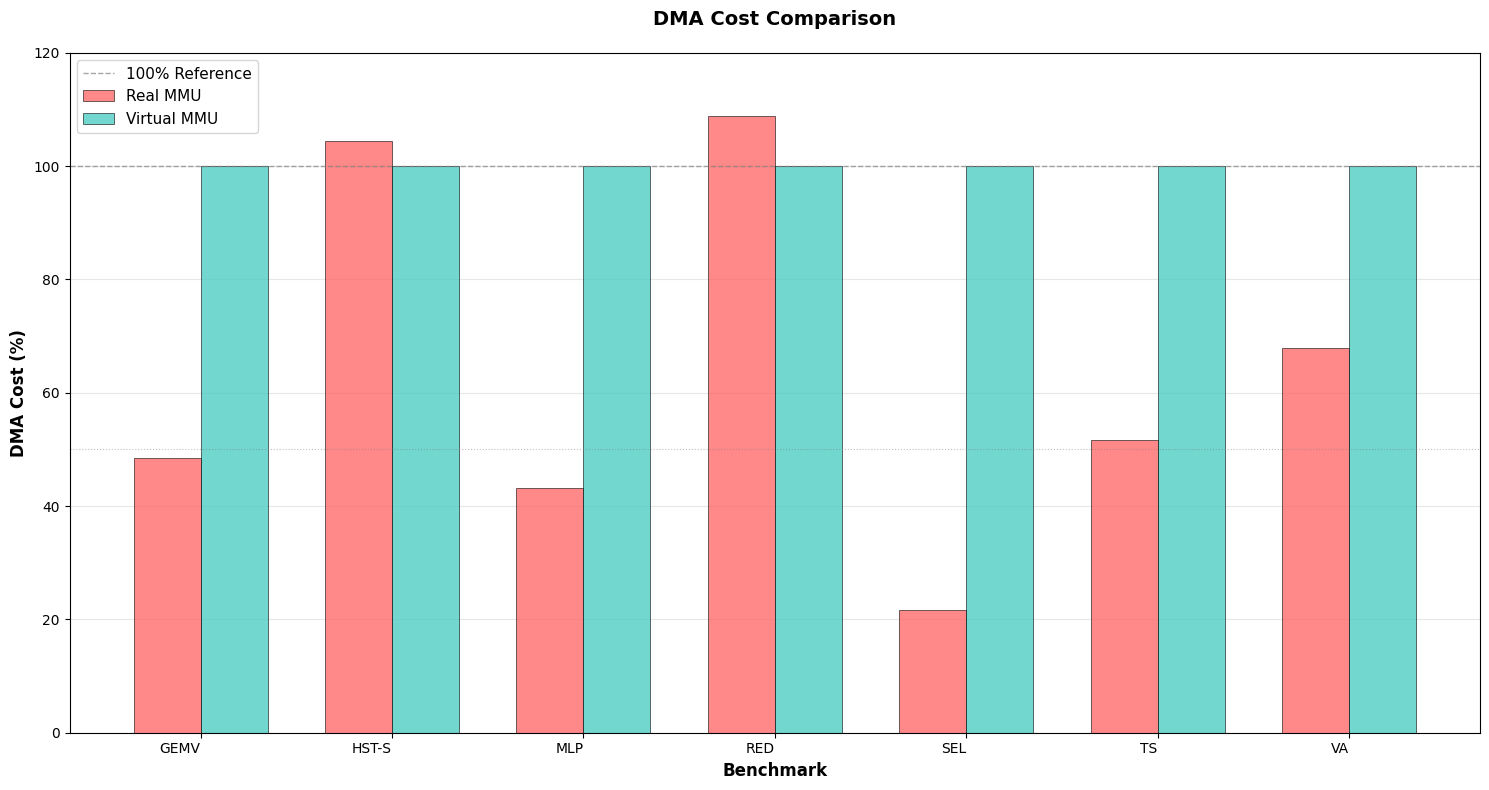

In [6]:
def create_dma_cost_comparison_chart(table1_data, table2_data, save_path=None):
    """Create comparison bar chart for dma_cost with percentage scaling"""
    # Convert to DataFrames
    df1 = pd.DataFrame(table1_data)
    df2 = pd.DataFrame(table2_data)
    
    # Find common
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.patches as mpatches


# Set font for better display
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

def read_csv_data(csv_file_path):
    """Read CSV file and extract code and dma_cost"""
    try:
        # Read CSV file
        df = pd.read_csv(csv_file_path)
        
        data = []
        for _, row in df.iterrows():
            code = str(row['code'])
            dma_cost = int(row['dma_cost']) if pd.notna(row['dma_cost']) else 0
            
            data.append({
                'code': code,
                'dma_cost': dma_cost
            })
        
        return data
    
    except Exception as e:
        print(f"Error reading CSV file {csv_file_path}: {e}")
        return None

def create_dma_cost_comparison_chart(table1_data, table2_data, save_path=None):
    """Create comparison bar chart for dma_cost with percentage scaling"""
    # Convert to DataFrames
    df1 = pd.DataFrame(table1_data)
    df2 = pd.DataFrame(table2_data)
    
    # Find common codes
    common_codes = list(set(df1['code']) & set(df2['code']))
    
    if not common_codes:
        print("No common codes found between tables!")
        return None
    
    # Filter data for common codes
    df1_filtered = df1[df1['code'].isin(common_codes)].copy()
    df2_filtered = df2[df2['code'].isin(common_codes)].copy()
    
    # Sort codes alphabetically for consistent display
    sorted_codes = sorted(common_codes)
    
    # Reorder dataframes according to sorted codes
    df1_filtered = df1_filtered.set_index('code').loc[sorted_codes]
    df2_filtered = df2_filtered.set_index('code').loc[sorted_codes]
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(15, 8))
    
    # Set bar width and positions
    bar_width = 0.35
    x_pos = np.arange(len(sorted_codes))
    
    # Colors for different tables
    colors = {
        'auto': '#FF6B6B',     # Red for Auto (without faho)
        'syn': '#4ECDC4'       # Teal for Syn (with faho)
    }
    
    # Extract dma_cost data and calculate percentages
    auto_dma_cost = [df1_filtered.loc[code, 'dma_cost'] for code in sorted_codes]
    syn_dma_cost = [df2_filtered.loc[code, 'dma_cost'] for code in sorted_codes]
    
    # Calculate percentage values (syn is always 100%, auto is relative to syn)
    syn_percentage = [100.0] * len(sorted_codes)  # Always 100%
    auto_percentage = []
    
    for auto_val, syn_val in zip(auto_dma_cost, syn_dma_cost):
        if syn_val > 0:
            auto_pct = (auto_val / syn_val) * 100
        else:
            auto_pct = 0
        auto_percentage.append(auto_pct)
    
    # Create bars
    bars1 = ax.bar(x_pos - bar_width/2, auto_percentage, 
                   bar_width, label='Real MMU', 
                   color=colors['auto'], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    bars2 = ax.bar(x_pos + bar_width/2, syn_percentage, 
                   bar_width, label='Virtual MMU', 
                   color=colors['syn'], alpha=0.8, edgecolor='black', linewidth=0.5)
    
    # Customize the chart
    ax.set_xlabel('Benchmark', fontsize=12, fontweight='bold')
    ax.set_ylabel('DMA Cost (%)', fontsize=12, fontweight='bold')
    ax.set_title('DMA Cost Comparison', 
                fontsize=14, fontweight='bold', pad=20)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(sorted_codes, fontsize=10, rotation=0, ha='right')
    
    # Set y-axis limit to 120% for better visualization
    ax.set_ylim(0, 120)
    
    # Add horizontal reference lines
    ax.axhline(y=100, color='gray', linestyle='--', alpha=0.7, linewidth=1, label='100% Reference')
    ax.axhline(y=50, color='gray', linestyle=':', alpha=0.5, linewidth=0.8)
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11)
    
    # Add grid for better readability
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_axisbelow(True)
    
    # Adjust layout
    plt.tight_layout()
    
    
    
    total_auto = 0
    total_syn = 0
    
    for i, code in enumerate(sorted_codes):
        auto_val = auto_dma_cost[i]
        syn_val = syn_dma_cost[i]
        auto_pct = auto_percentage[i]
        overhead_pct = auto_pct - 100
        
        total_auto += auto_val
        total_syn += syn_val
        
        print(f"{code:<12} {auto_val:<15,} {syn_val:<15,} {auto_pct:<15.1f}% {overhead_pct:<12.1f}%")
    
    print("-" * 85)
    total_auto_pct = (total_auto / total_syn * 100) if total_syn > 0 else 0
    total_overhead_pct = total_auto_pct - 100
    print(f"{'TOTAL':<12} {total_auto:<15,} {total_syn:<15,} {total_auto_pct:<15.1f}% {total_overhead_pct:<12.1f}%")
    
    # Save or show the plot
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"\nChart saved to: {save_path}")
    else:
        plt.show()
    
    return fig, ax, sorted_codes

def main(csv_file1=None, csv_file2=None):
    """Main function to run the DMA cost comparison"""
    print("=== DMA Cost Comparison Tool ===\n")
    
    # Get CSV file paths
    if not csv_file1:
        csv_file1 = input("Enter path to first CSV file (without faho): ").strip()
    if not csv_file2:
        csv_file2 = input("Enter path to second CSV file (with faho): ").strip()
    
    # Read CSV data
    table1_data = read_csv_data(csv_file1)
    table2_data = read_csv_data(csv_file2)
    
    if table1_data is None or table2_data is None:
        print("Failed to read CSV files. Please check file paths and format.")
        return
    
    # Create comparison chart
    print("\nGenerating DMA cost comparison chart...")
    result = create_dma_cost_comparison_chart(table1_data, table2_data, save_path="dma_cost_comparison.png")
    
    if result is None:
        print("Failed to create chart.")
        return
    
    fig, ax, sorted_codes = result
    
    print("\nDMA cost comparison chart generated successfully!")

if __name__ == "__main__":
    main("mmu-2/result.csv", "upim/result.csv")